<center><h1>You_Shihua_HW4</h1></center>
<br>
<br>

Name: Shihua You
<br>
Github Username: youshihuaaria

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os, glob, re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.utils import resample
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, accuracy_score)

warnings.filterwarnings("ignore")

Get the AReM Data Set

In [2]:
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
cols = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

dfs = []
train_dfs = []
test_dfs = []
for act in activities:
    for f in sorted(glob.glob(f"AReM/{act}/dataset*.csv")):
        no = int(re.findall(r"\d+", os.path.basename(f))[0])
        df = pd.read_csv(f, comment="#", header=None, names=cols, sep=r"[,\s]+", usecols=range(7), engine="python")
        df["activity_name"] = act
        df["dataset"] = no
        dfs.append(df)

        if act in ["bending1", "bending2"] and no <= 2:
            test_dfs.append(df)
        elif act not in ["bending1", "bending2"] and no <= 3:
            test_dfs.append(df)
        else:
            train_dfs.append(df)

data = pd.concat(dfs, ignore_index=True)
train = pd.concat(train_dfs, ignore_index=True)
test = pd.concat(test_dfs, ignore_index=True)

data.head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,activity_name,dataset
0,0,39.25,0.43,22.75,0.43,33.75,1.3,bending1,1
1,250,39.25,0.43,23.00,0.00,33.00,0.0,bending1,1
2,500,39.25,0.43,23.25,0.43,33.00,0.0,bending1,1
3,750,39.50,0.50,23.00,0.71,33.00,0.0,bending1,1
4,1000,39.50,0.50,24.00,0.00,33.00,0.0,bending1,1


### (b) Splitting Data

In [3]:
display(train.head())
display(test.head())

print(len(test_dfs), len(train_dfs))

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,activity_name,dataset
0,0,42.00,0.71,21.25,0.43,30.00,0.00,bending1,3
1,250,41.50,0.50,20.25,1.48,31.25,1.09,bending1,3
2,500,41.50,0.50,14.25,1.92,33.00,0.00,bending1,3
3,750,40.75,0.83,15.75,0.43,33.00,0.00,bending1,3
4,1000,40.00,0.71,20.00,2.74,32.75,0.43,bending1,3


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,activity_name,dataset
0,0,39.25,0.43,22.75,0.43,33.75,1.3,bending1,1
1,250,39.25,0.43,23.00,0.00,33.00,0.0,bending1,1
2,500,39.25,0.43,23.25,0.43,33.00,0.0,bending1,1
3,750,39.50,0.50,23.00,0.71,33.00,0.0,bending1,1
4,1000,39.50,0.50,24.00,0.00,33.00,0.0,bending1,1


19 69


### (c) Feature Extraction

In [4]:
series_cols = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

rows = []
for df in dfs:
    row = {}
    for i, c in enumerate(series_cols, 1):
        s = df[c]
        row[f"min{i}"] = s.min()
        row[f"max{i}"] = s.max()
        row[f"mean{i}"] = s.mean()
        row[f"median{i}"] = s.median()
        row[f"std{i}"] = s.std()
        row[f"1st quart{i}"] = s.quantile(0.25)
        row[f"3rd quart{i}"] = s.quantile(0.75)
    rows.append(row)

features = pd.DataFrame(rows)
print(len(features))

features_std = features.std()

bootstrap_stds = []
for b in range(1000):
    sample = features.sample(n=len(features), replace=True)
    bootstrap_stds.append(sample.std())

boot_stds = pd.DataFrame(bootstrap_stds)

result = pd.DataFrame({
    "std": features_std,
    "CI_lower": boot_stds.quantile(0.05),
    "CI_upper": boot_stds.quantile(0.95),
})

result

88


,std,CI_lower,CI_upper
min1,9.569975,8.297257,10.739505
max1,4.394362,3.344324,5.191414
mean1,5.335718,4.710819,5.873793
median1,5.440054,4.776213,5.983136
std1,1.772153,1.573330,1.955719
1st quart1,6.153590,5.606676,6.631788
3rd quart1,5.138925,4.343971,5.863488
min2,0.000000,0.000000,0.000000
max2,5.062729,4.645525,5.393509
mean2,1.574164,1.406674,1.701700


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

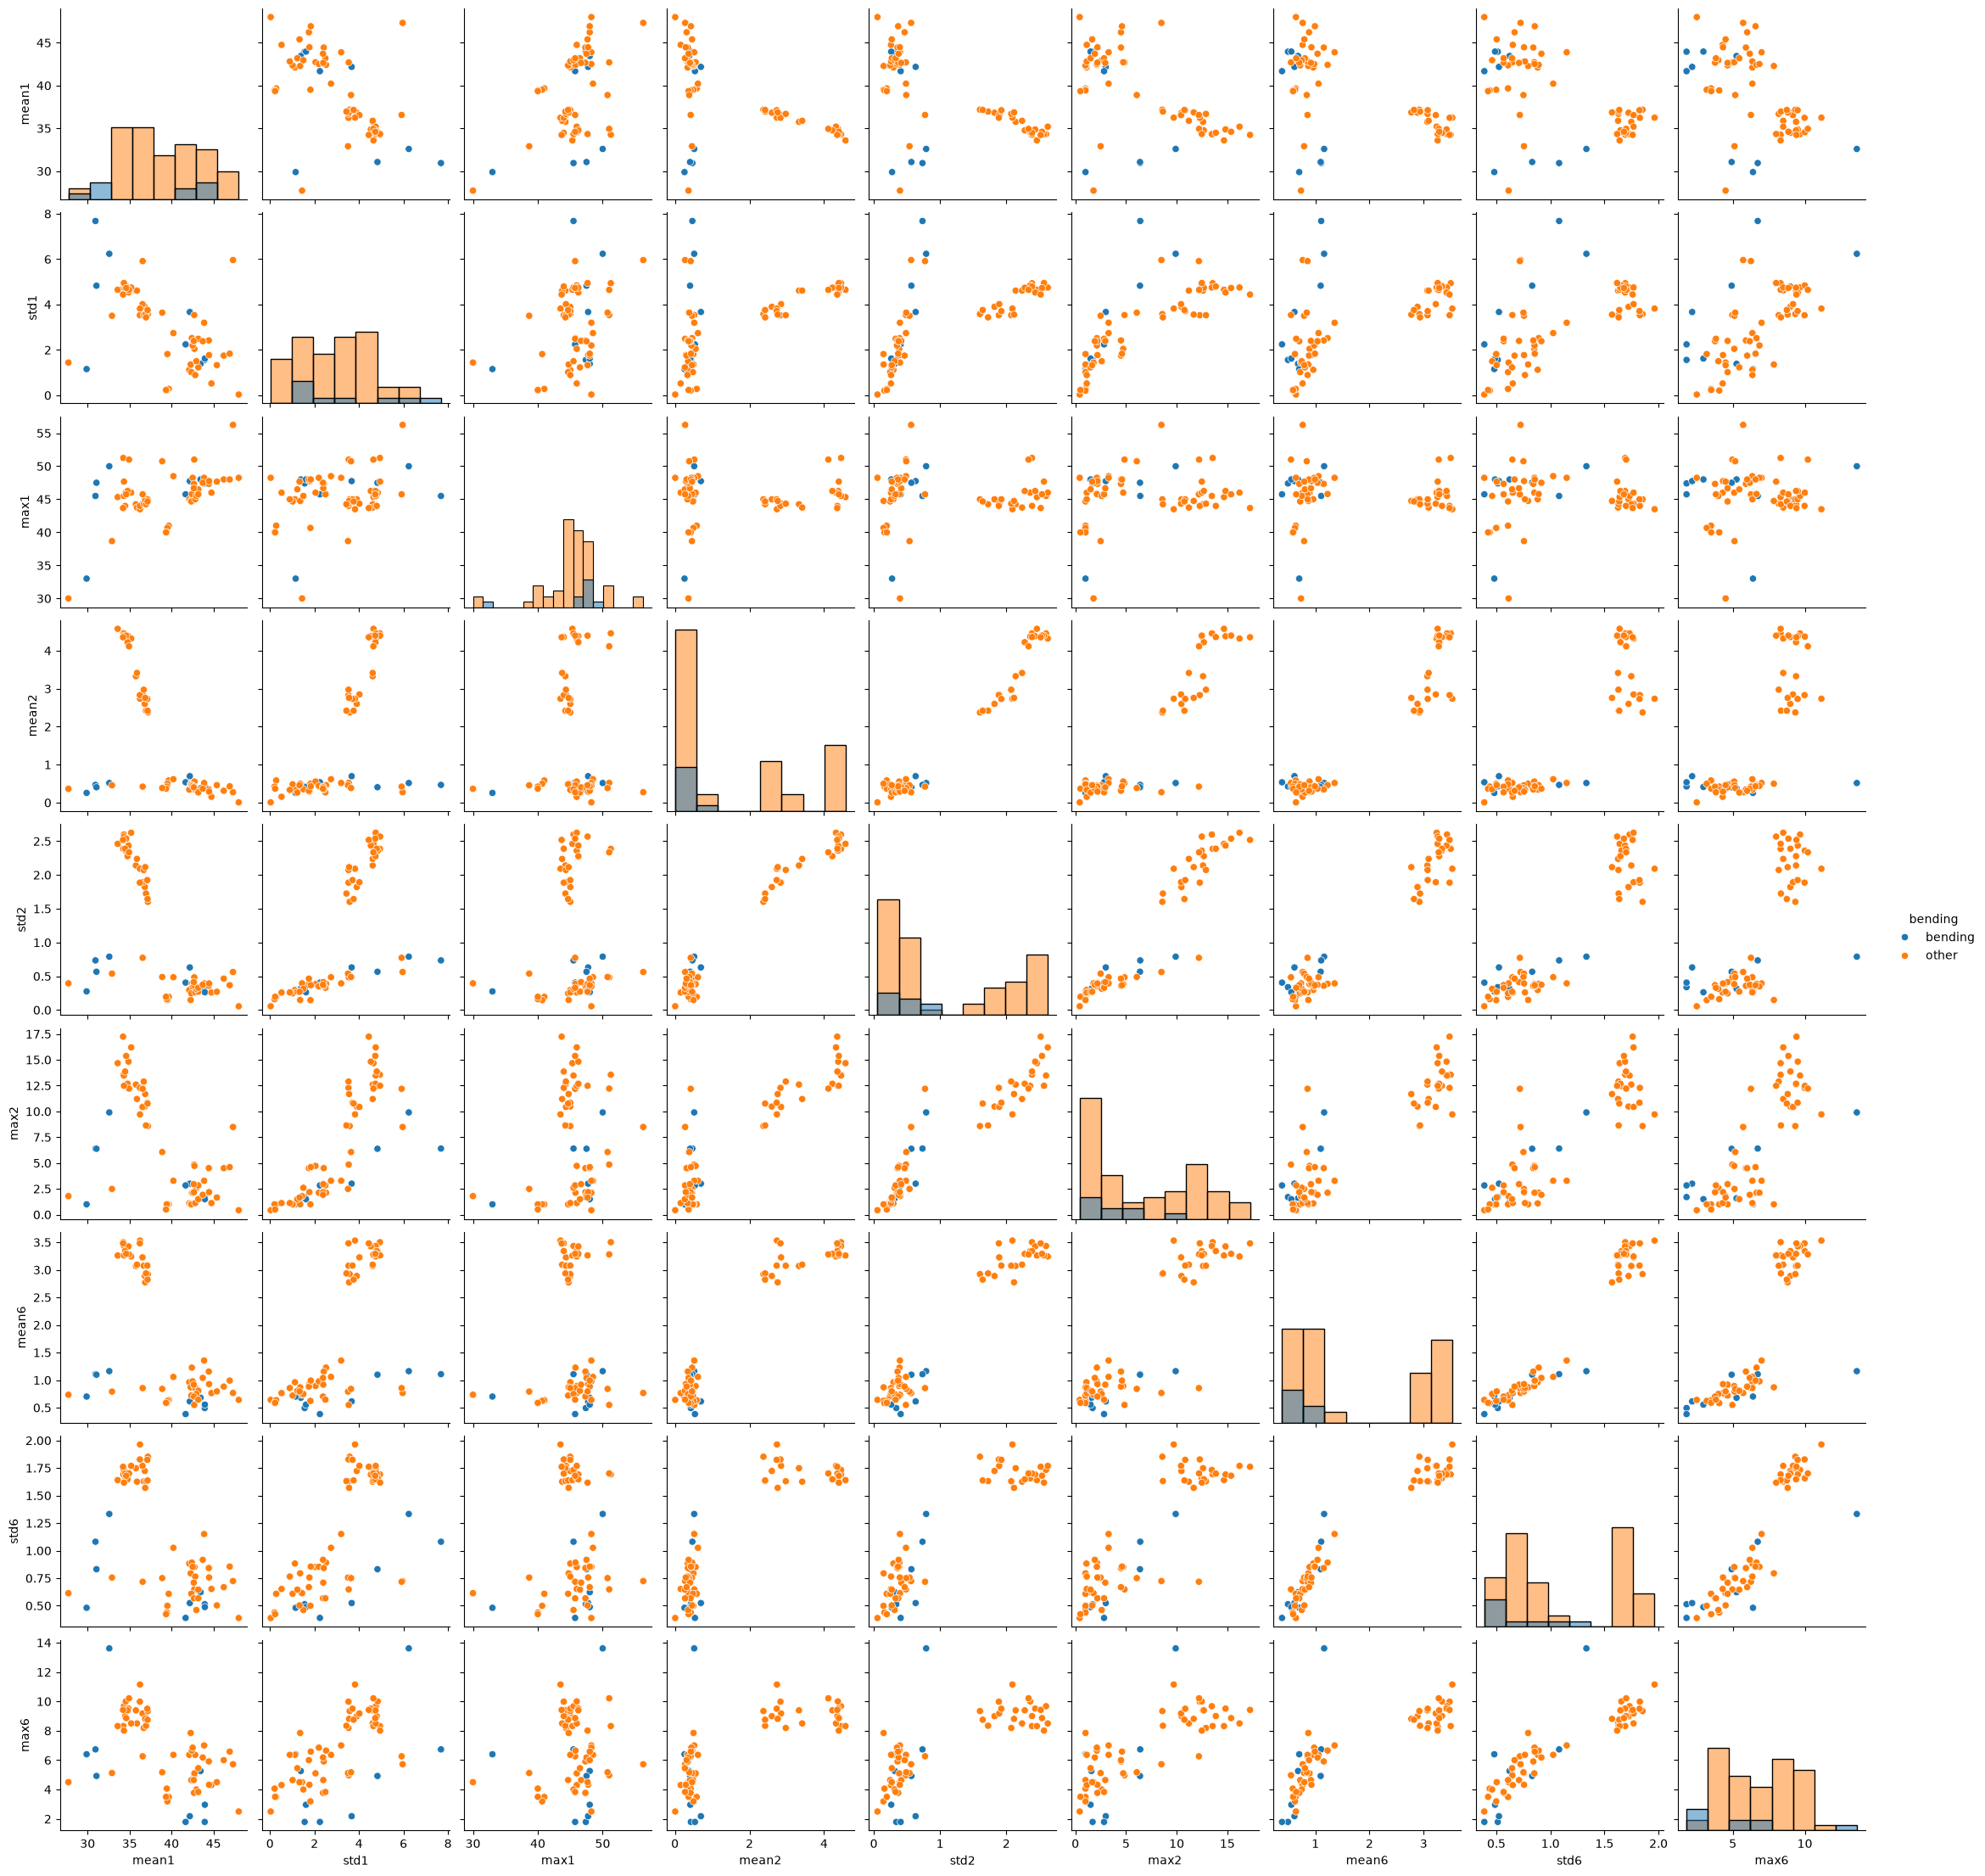

In [5]:
cols_plot = ["mean1", "std1", "max1", "mean2", "std2", "max2", "mean6", "std6", "max6"]

test_ids = {id(d) for d in test_dfs}
is_train = [id(d) not in test_ids for d in dfs]

plot_df = features.loc[is_train, cols_plot].copy()
plot_df["bending"] = ["bending" if d["activity_name"].iloc[0] in ["bending1", "bending2"] else "other"
                      for d in train_dfs]

sns.pairplot(plot_df, hue="bending", diag_kind="hist")
plt.show()

#### ii. Splitted Plots

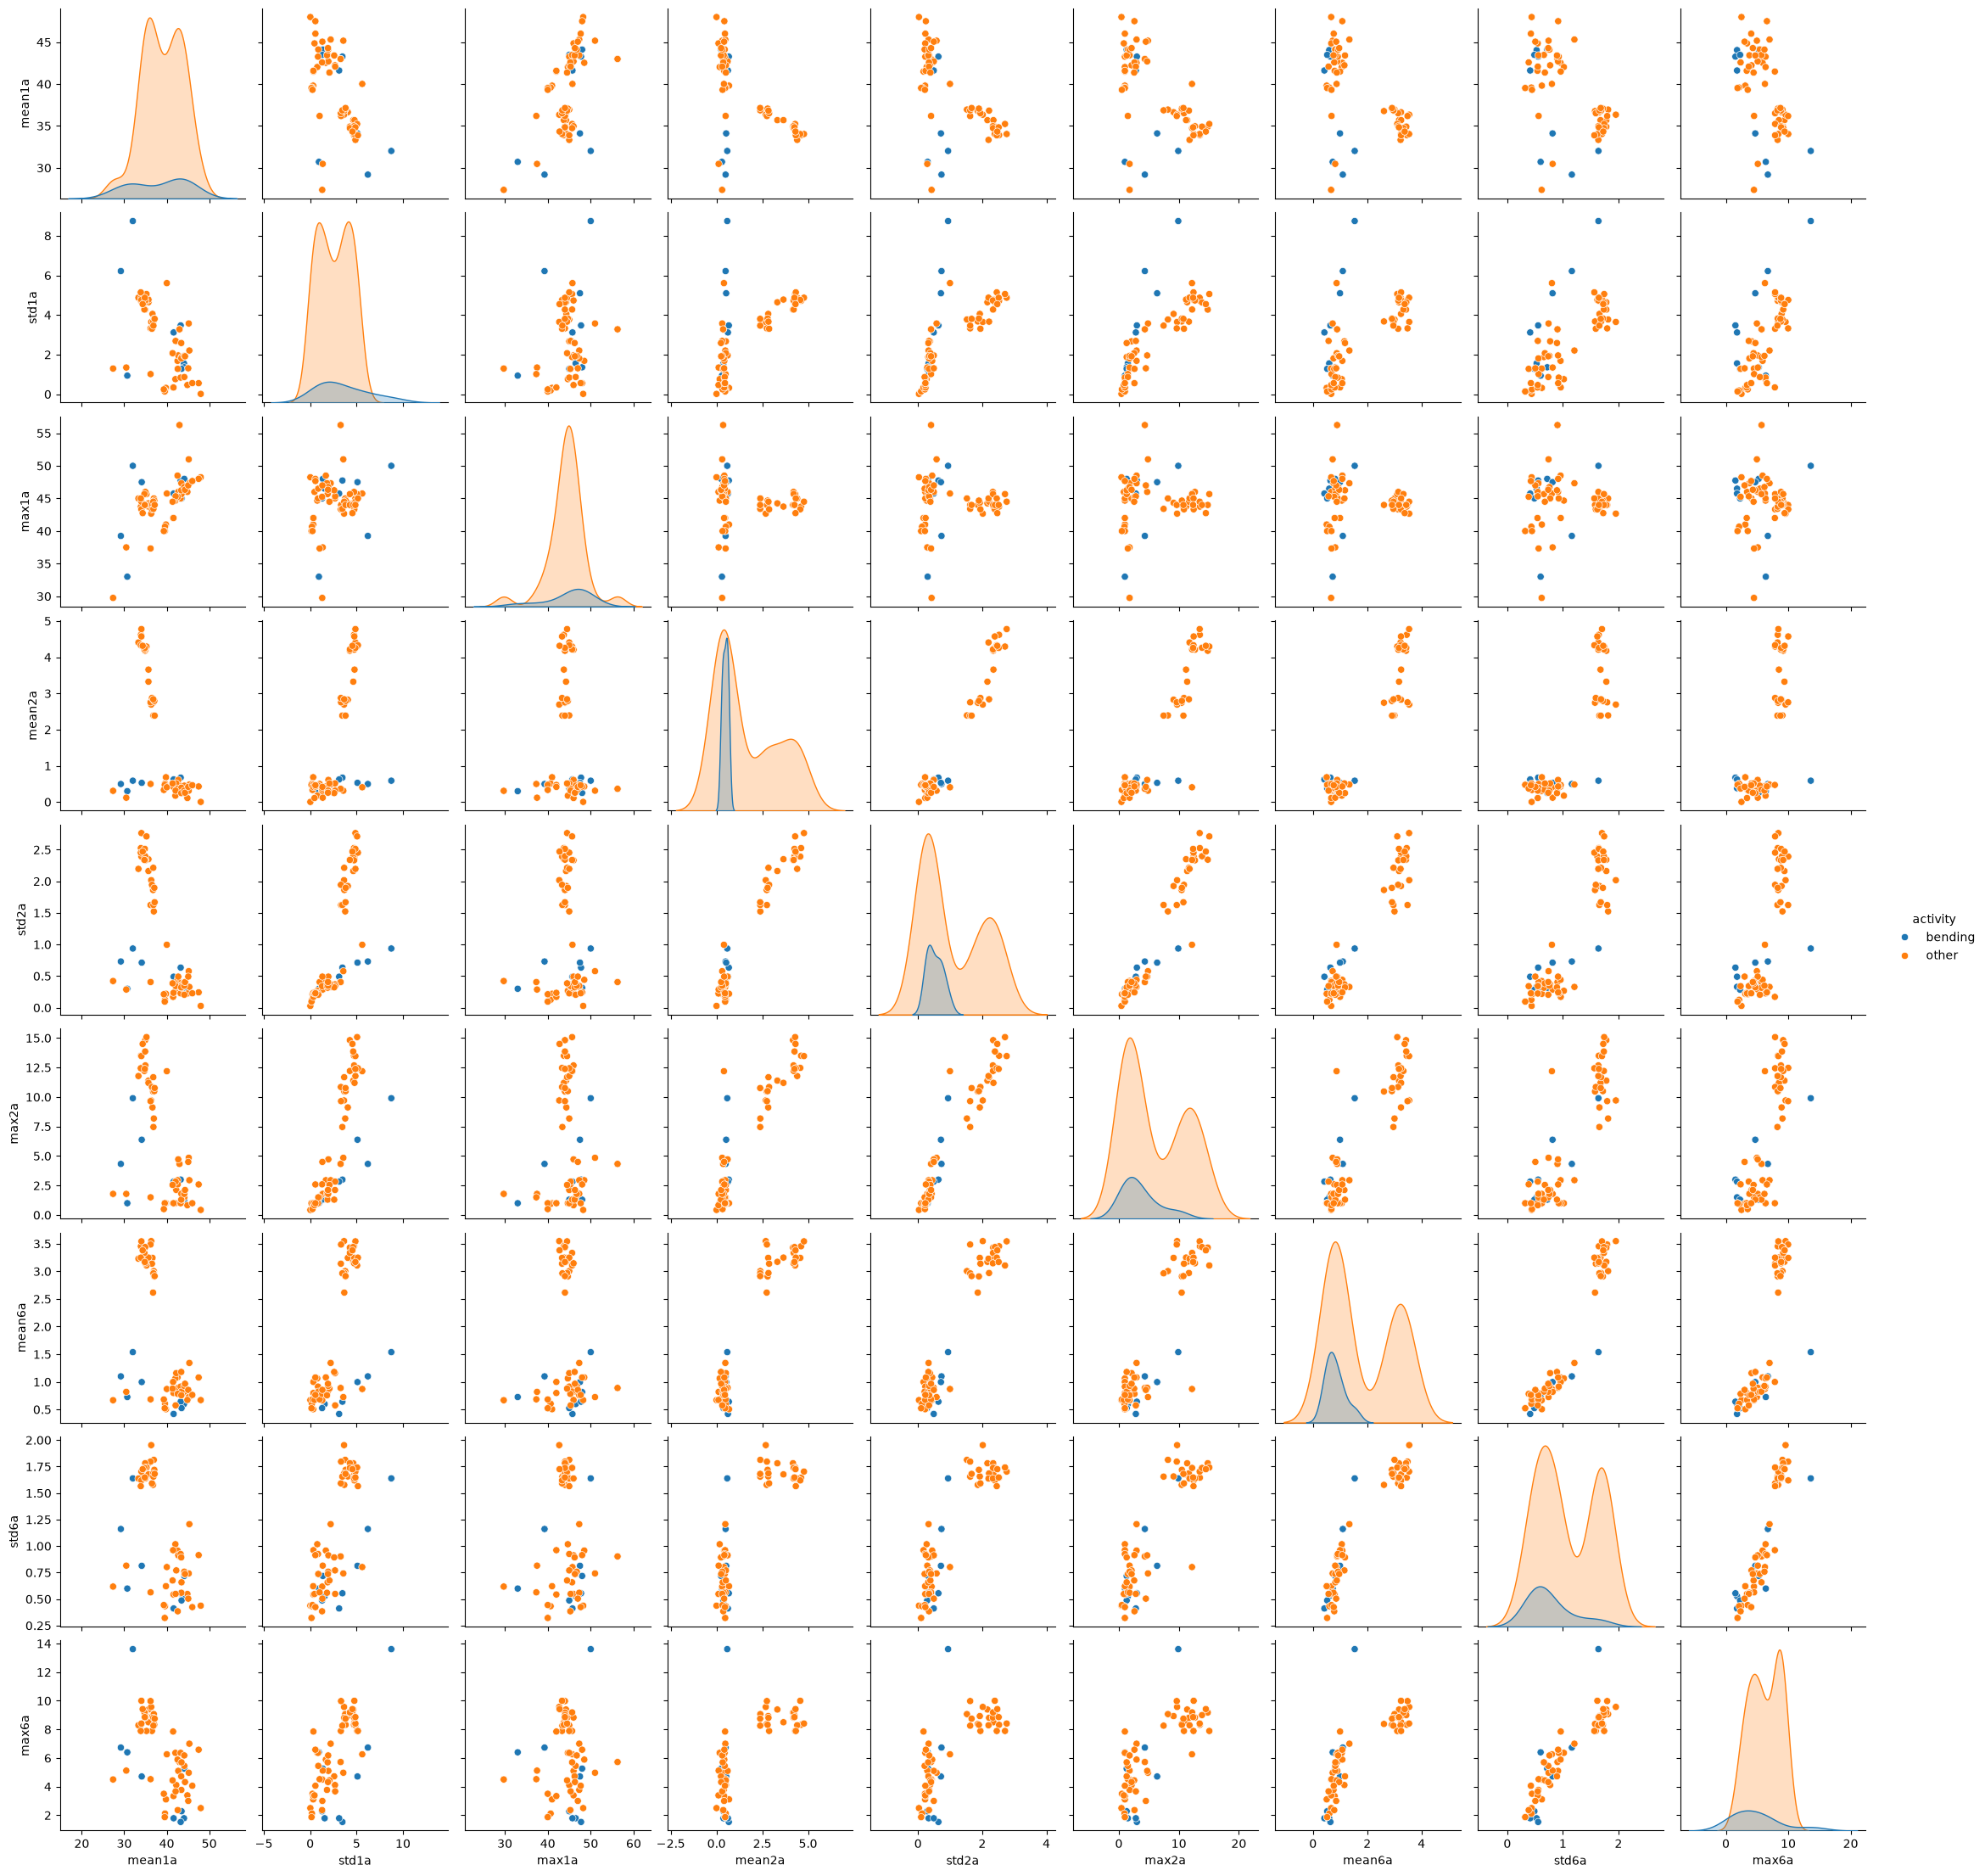

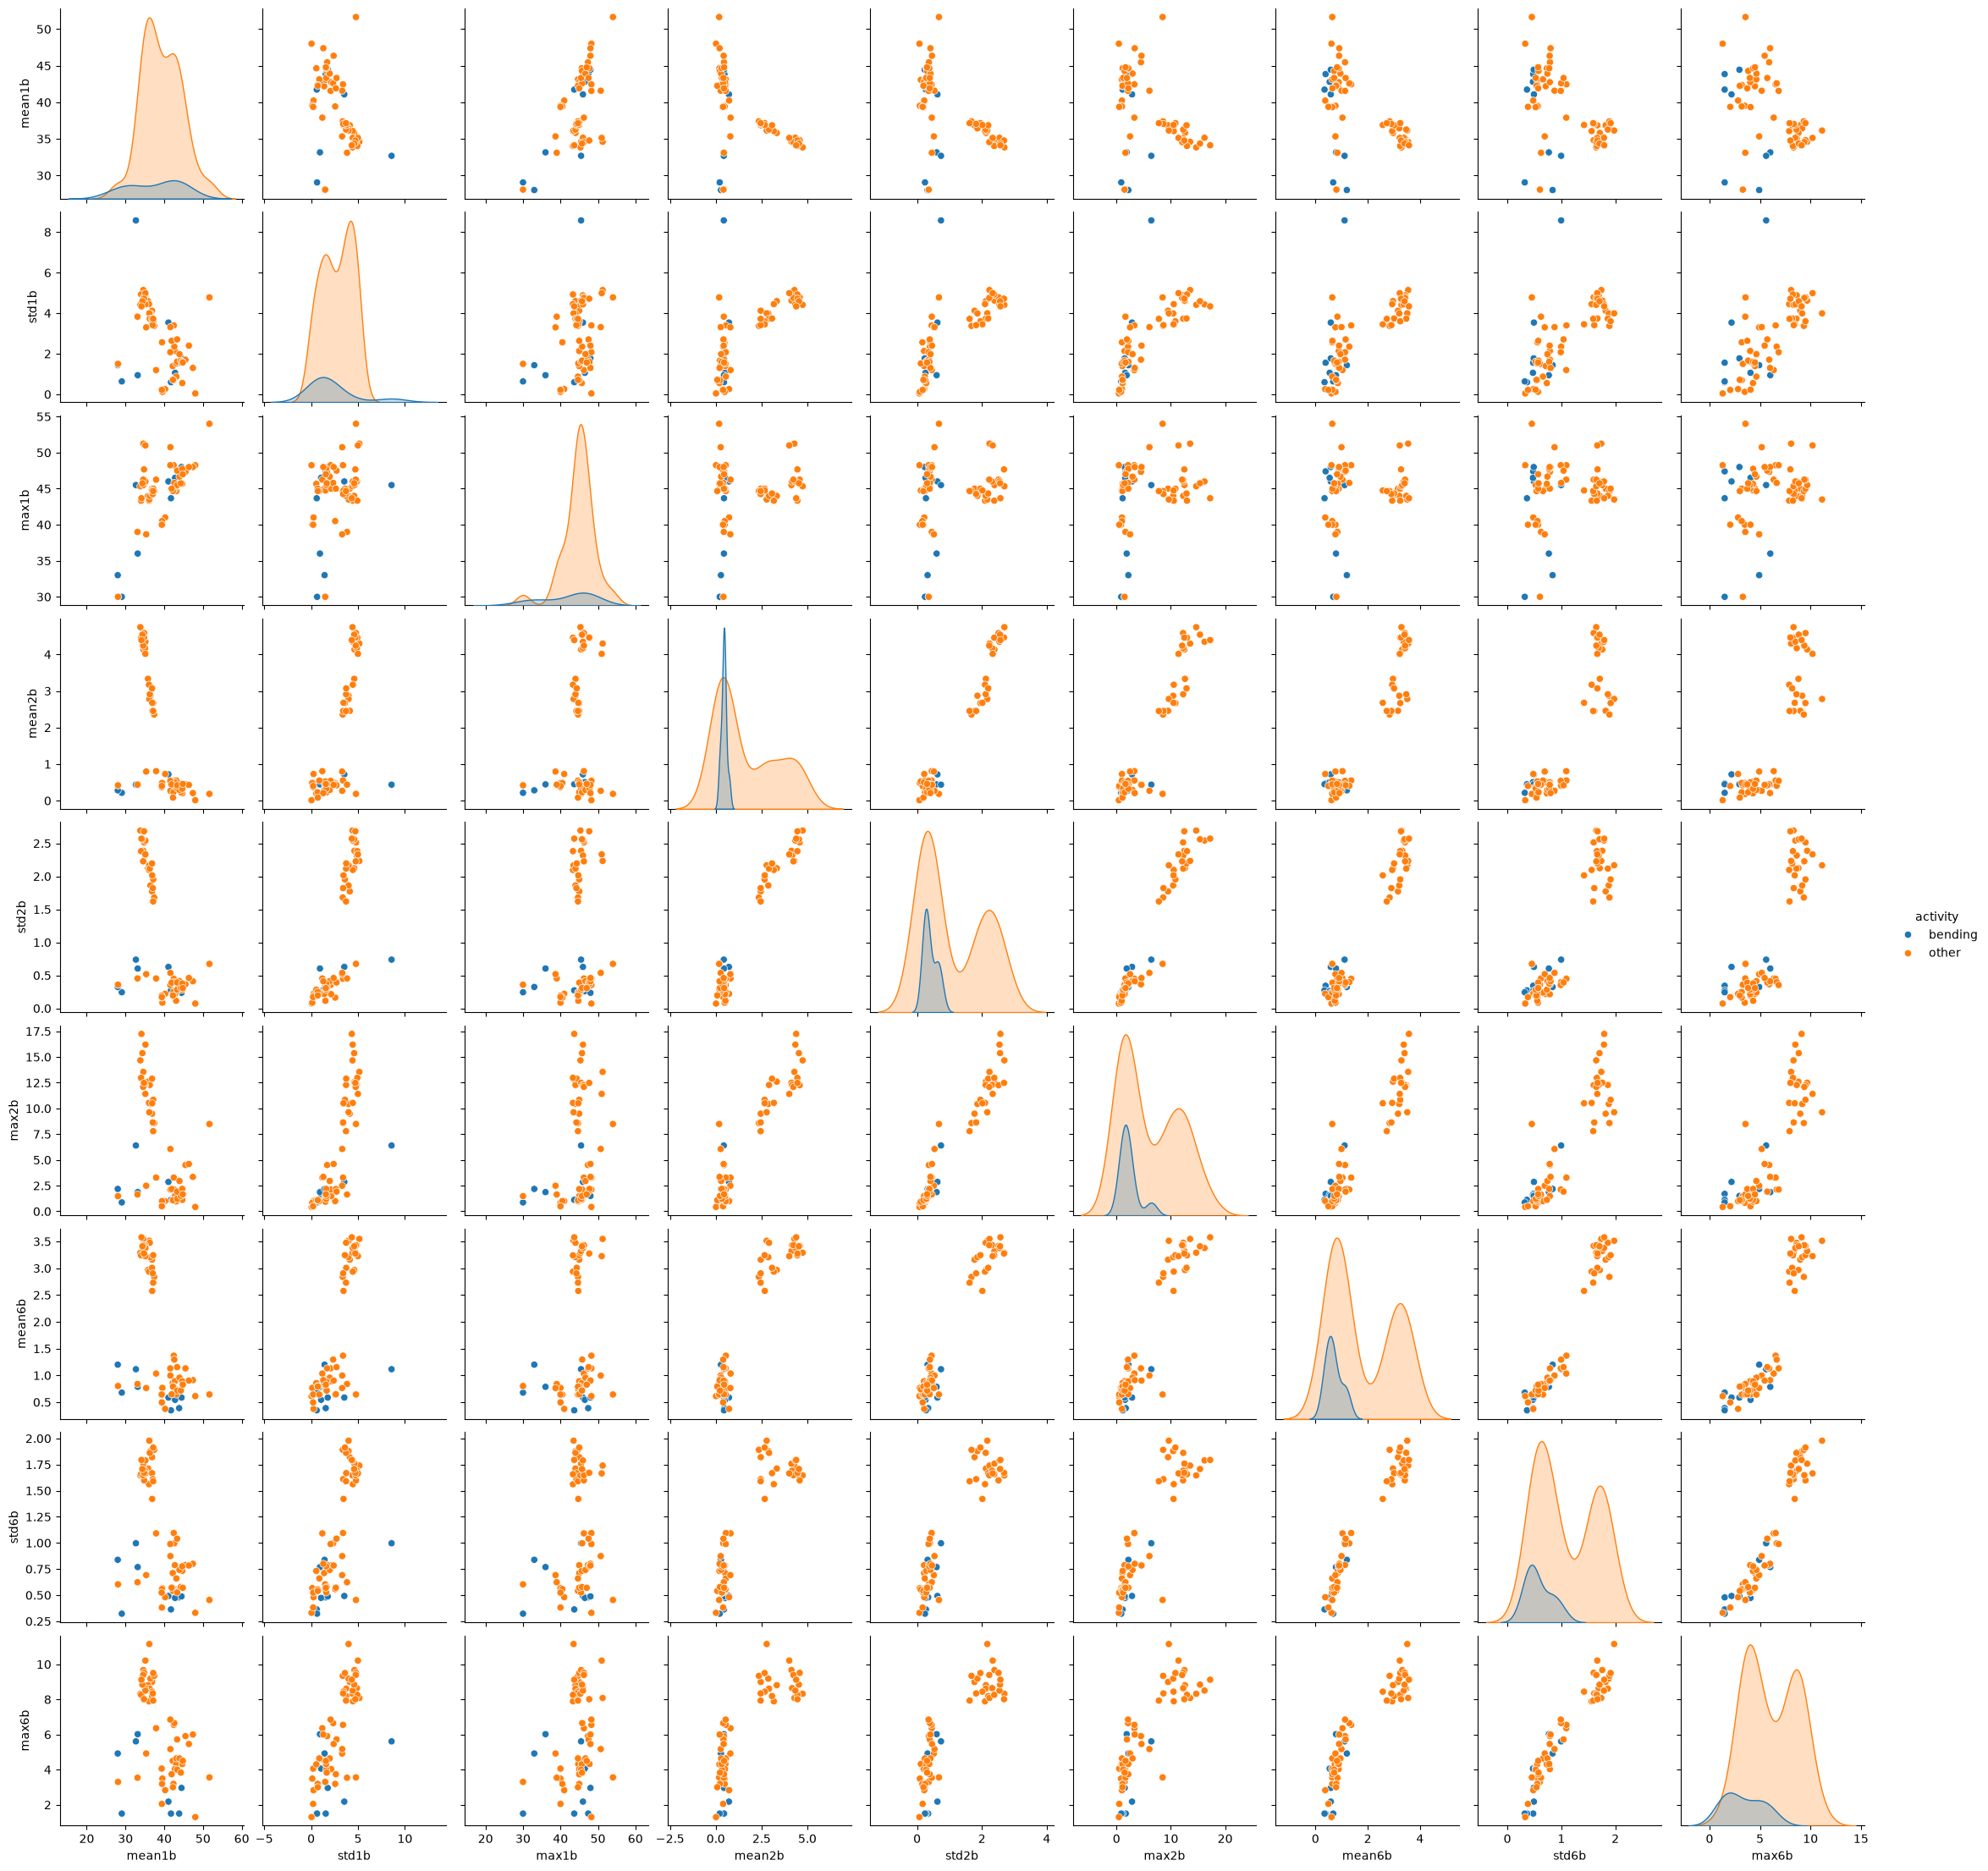

In [6]:
series = {1: "avg_rss12", 2: "var_rss12", 6: "var_rss23"}

rows = []
labels = []
for df in dfs:
    act, no = df["activity_name"].iloc[0], df["dataset"].iloc[0]
    is_bend = act in ["bending1", "bending2"]
    is_test_inst = (no <= 2) if is_bend else (no <= 3)
    if is_test_inst:
        continue

    row = {}
    for i, c in series.items():
        for part, piece in [("a", df[c].iloc[:240]), ("b", df[c].iloc[240:])]:
            row[f"mean{i}{part}"] = piece.mean()
            row[f"std{i}{part}"] = piece.std()
            row[f"max{i}{part}"] = piece.max()
    rows.append(row)
    labels.append("bending" if is_bend else "other")

split_df = pd.DataFrame(rows)
split_df["activity"] = labels

first = [f"{s}{i}a" for i in [1, 2, 6] for s in ["mean", "std", "max"]]
second = [f"{s}{i}b" for i in [1, 2, 6] for s in ["mean", "std", "max"]]

sns.pairplot(split_df, vars=first, hue="activity")
plt.show()

sns.pairplot(split_df, vars=second, hue="activity")
plt.show()

No considerable difference. The plots of the first half and the second half look very similar to each other and to the plots in 2(a)i. In all of them, bending (blue) is separated from the activities with large mean2, std2, mean6 and std6, but it overlaps heavily with the other activities that have small values. So splitting each series into two parts does not make the classes easier to separate.

#### iii. Time Series Segments

In [7]:
def make_features(instances, l):
    rows = []
    for df in instances:
        row = []
        for c in series_cols:
            for piece in np.array_split(df[c].values, l):
                row += [piece.min(), piece.max(), piece.mean(), np.median(piece),
                        piece.std(ddof=1), np.percentile(piece, 25), np.percentile(piece, 75)]
        rows.append(row)
    return np.array(rows)

y = np.array([1 if df["activity_name"].iloc[0] in ["bending1", "bending2"] else 0 for df in train_dfs])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
P_RANGE = range(1, 21)
results = []

for l in range(1, 21):
    X = make_features(train_dfs, l)
    fold_acc = np.zeros((5, len(P_RANGE)))
    for k, (tr, va) in enumerate(cv.split(X, y)):
        scaler = StandardScaler().fit(X[tr])                      
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])
        rank = RFE(LogisticRegression(C=1e10, max_iter=100), n_features_to_select=1).fit(Xtr, y[tr]).ranking_
        for m, p in enumerate(P_RANGE):
            keep = rank <= p                                      
            clf = LogisticRegression(C=1e10, max_iter=100).fit(Xtr[:, keep], y[tr])
            fold_acc[k, m] = clf.score(Xva[:, keep], y[va])
    for m, p in enumerate(P_RANGE):
        results.append((l, p, fold_acc[:, m].mean()))
    print("l =", l, "done")

res = pd.DataFrame(results, columns=["l", "p", "cv_accuracy"])
res.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).head(10)

l = 1 done
l = 2 done
l = 3 done
l = 4 done
l = 5 done
l = 6 done
l = 7 done
l = 8 done
l = 9 done
l = 10 done
l = 11 done
l = 12 done
l = 13 done
l = 14 done
l = 15 done
l = 16 done
l = 17 done
l = 18 done
l = 19 done
l = 20 done


,l,p,cv_accuracy
366,19,7,0.985714
187,10,8,0.985714
367,19,8,0.985714
368,19,9,0.985714
189,10,10,0.985714
369,19,10,0.985714
190,10,11,0.985714
370,19,11,0.985714
191,10,12,0.985714
371,19,12,0.985714


Right way: because the selected features depend on the data, feature selection (RFE) and standardization are done inside each CV fold, using only the training part of that fold. The validation fold is used only to compute accuracy.
Wrong way: select the features (or fit the scaler) on all the training data first and then run CV. The validation folds have already influenced the choice of features, so the CV accuracy is too optimistic.
Only 9 of the 69 training instances are bending, so I use stratified 5-fold CV to make sure every fold contains bending instances.
The best pair is (l, p) = (19, 7) with CV accuracy 0.986. Many pairs tie, and I chose the one with the smallest p.

#### iv. Confusion Matrix

Selected features: ['3rd_quart1_12', 'std3_15', 'min5_3', 'mean5_3', '1st_quart5_3', 'min5_17', 'std5_18']


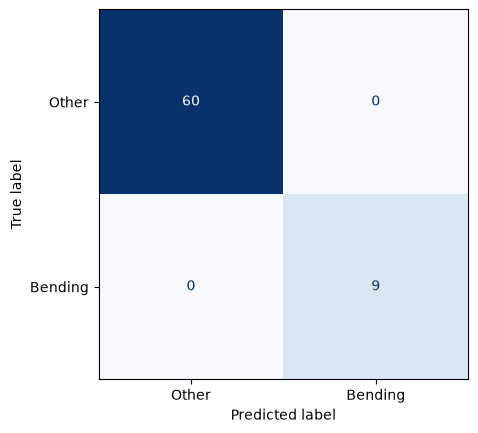

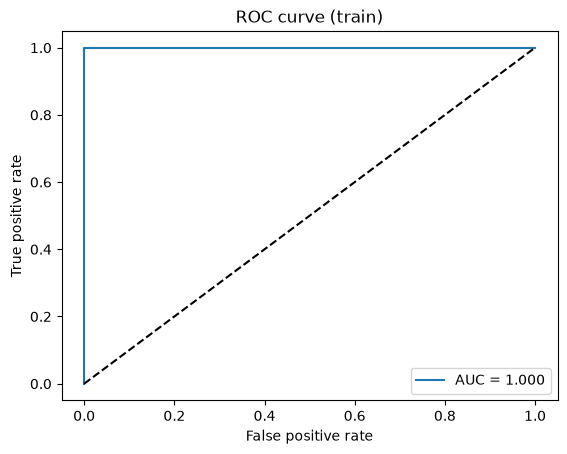

,beta,p-value
const,-36.242078,0.999909
3rd_quart1_12,-5.362762,0.999991
std3_15,-9.749737,0.999987
min5_3,9.976933,0.999988
mean5_3,-7.300774,0.999997
1st_quart5_3,31.764098,0.999986
min5_17,7.528715,0.999989
std5_18,-4.542666,0.999990


In [8]:
best_l, best_p = 19, 7

X = make_features(train_dfs, best_l)
stats = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
names = [f"{s}{i}_{k}" for i in range(1, 7) for k in range(1, best_l + 1) for s in stats]

Xs = StandardScaler().fit_transform(X)
rfe = RFE(LogisticRegression(C=1e10, max_iter=1000), n_features_to_select=best_p).fit(Xs, y)
selected = [n for n, keep in zip(names, rfe.support_) if keep]
Xsel = Xs[:, rfe.support_]
print("Selected features:", selected)

clf = LogisticRegression(C=1e10, max_iter=1000).fit(Xsel, y)
pred = clf.predict(Xsel)
prob = clf.predict_proba(Xsel)[:, 1]

ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Other", "Bending"], cmap="Blues", colorbar=False)
plt.show()

fpr, tpr, _ = roc_curve(y, prob)
plt.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (train)")
plt.legend()
plt.show()

logit = sm.Logit(y, sm.add_constant(pd.DataFrame(Xsel, columns=selected))).fit(disp=0, maxiter=200)
pd.DataFrame({"beta": logit.params, "p-value": logit.pvalues})

#### v. Test Classifier

[[15  0]
 [ 1  3]]
Test accuracy: 0.9473684210526315


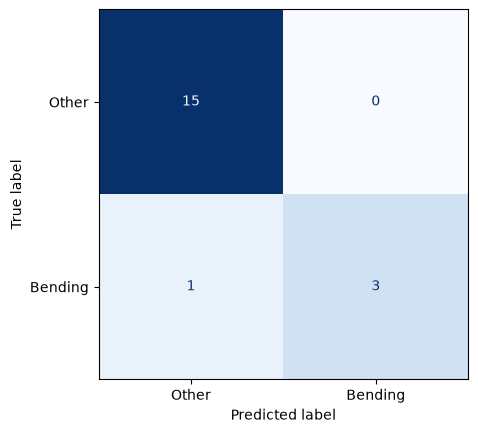

In [9]:
test_inst, y_test = [], []
for df in dfs:
    act, no = df["activity_name"].iloc[0], df["dataset"].iloc[0]
    is_bend = act in ["bending1", "bending2"]
    if (no <= 2) if is_bend else (no <= 3):
        test_inst.append(df)
        y_test.append(1 if is_bend else 0)
y_test = np.array(y_test)

X_test = make_features(test_inst, best_l)

scaler = StandardScaler().fit(X) 
X_test_sel = scaler.transform(X_test)[:, rfe.support_]

test_pred = clf.predict(X_test_sel)
print(confusion_matrix(y_test, test_pred))
print("Test accuracy:", (test_pred == y_test).mean())

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Other", "Bending"], cmap="Blues", colorbar=False)
plt.show()

The test accuracy is 0.947 (18 of 19 correct; one bending instance is misclassified), slightly lower than the cross-validation accuracy of 0.986. The difference is small, and the test set is tiny: one instance changes the accuracy by about 5%.

#### vi. Separation

Yes. The training data are perfectly separated: the confusion matrix has no errors and the AUC is 1.0. This makes the logistic regression parameters unstable. The optimizer does not converge, the coefficients are very large, and all p-values are close to 1. This happens because there are only 9 bending instances but hundreds of features, so it is easy to separate the classes.

#### vii. Imbalance

Intercept before: -7.064021523891403
Intercept after : -8.961141508777285
train confusion matrix:
 [[60  0]
 [ 0  9]]
test confusion matrix:
 [[14  1]
 [ 1  3]]


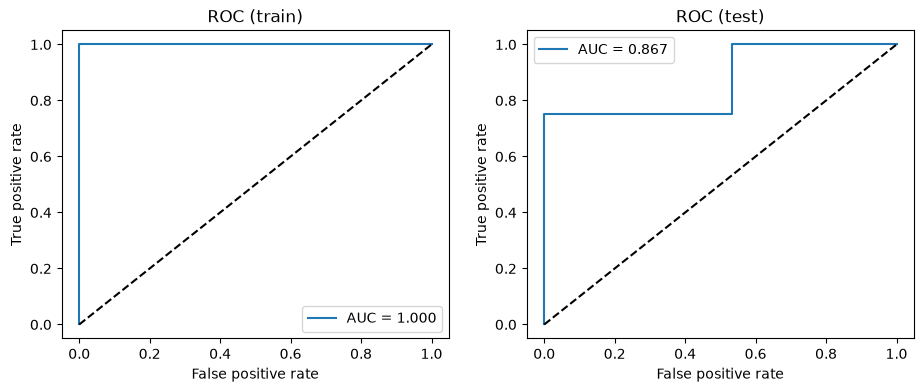

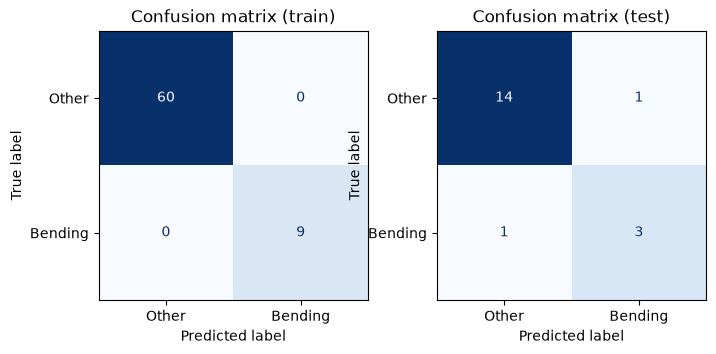

In [10]:
rng = np.random.default_rng(42)
case_idx = np.where(y == 1)[0]
ctrl_idx = rng.choice(np.where(y == 0)[0], size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, ctrl_idx]

cc_clf = LogisticRegression(C=1e10, max_iter=1000).fit(Xsel[cc_idx], y[cc_idx])

pi, pi_s = y.mean(), y[cc_idx].mean()
adjust = np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))
print("Intercept before:", cc_clf.intercept_[0])
cc_clf.intercept_ = cc_clf.intercept_ + adjust
print("Intercept after :", cc_clf.intercept_[0])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, Xe, ye, ax in [("train", Xsel, y, axes[0]), ("test", X_test_sel, y_test, axes[1])]:
    prob = cc_clf.predict_proba(Xe)[:, 1]
    print(name, "confusion matrix:\n", confusion_matrix(ye, cc_clf.predict(Xe)))
    fpr, tpr, _ = roc_curve(ye, prob)
    ax.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC ({name})")
    ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for name, Xe, ye, ax in [("train", Xsel, y, axes[0]), ("test", X_test_sel, y_test, axes[1])]:
    ConfusionMatrixDisplay.from_predictions(ye, cc_clf.predict(Xe), display_labels=["Other", "Bending"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Confusion matrix ({name})")
plt.show()

Yes, the classes are imbalanced: 9 bending vs. 60 other in the training set, and 4 vs. 15 in the test set. I built a case-control sample with all 9 bending instances and 9 randomly drawn other instances, fitted a logistic regression, and adjusted the intercept from -7.06 to -8.96 to match the true class proportion (9/69). The model classifies the training set perfectly (AUC = 1.0). On the test set, accuracy is 0.895 and AUC is 0.867, slightly worse than before because only 18 training instances were used.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
C_grid = np.logspace(-2, 2, 17)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for l in range(1, 21):
    X_l = make_features(train_dfs, l)
    for C in C_grid:
        pipe = Pipeline([
            ("scale", StandardScaler()),
            ("lr", LogisticRegression(penalty="l1", solver="liblinear", C=C)),
        ])
        acc = cross_val_score(pipe, X_l, y, cv=cv).mean()
        rows.append((l, C, acc))
    print("l =", l, "done")

res_l1 = pd.DataFrame(rows, columns=["l", "C", "cv_accuracy"])
res_l1.sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True]).head(10)

l = 1 done
l = 2 done
l = 3 done
l = 4 done
l = 5 done
l = 6 done
l = 7 done
l = 8 done
l = 9 done
l = 10 done
l = 11 done
l = 12 done
l = 13 done
l = 14 done
l = 15 done
l = 16 done
l = 17 done
l = 18 done
l = 19 done
l = 20 done


,l,C,cv_accuracy
9,1,1.778279,0.971429
10,1,3.162278,0.971429
29,2,10.000000,0.971429
169,10,100.000000,0.971429
195,12,1.000000,0.971429
196,12,1.778279,0.971429
197,12,3.162278,0.971429
198,12,5.623413,0.971429
199,12,10.000000,0.971429
200,12,17.782794,0.971429


I cross-validated both l and C (C = 1/λ) with stratified 5-fold cross-validation, with standardization inside each fold. Many pairs tie at the best CV accuracy of 0.971; I chose the simplest one: l = 1 and C ≈ 1.78.

#### ii. Comparison

The two methods perform similarly. RFE reaches a cross-validation accuracy of 0.986, and L1-penalized logistic regression reaches 0.971; the difference is only one instance out of 69, so neither is clearly better. L1-penalized logistic regression is easier to implement: it selects variables and fits the model in one step by setting penalty="l1" and tuning C, while RFE repeatedly refits the model and requires choosing the number of features p. Selecting variables with p-values is even harder here, because the classes are perfectly separated and all p-values are close to 1.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [12]:
train_act, test_act = [], []
for df in dfs:
    act, no = df["activity_name"].iloc[0], df["dataset"].iloc[0]
    is_bend = act in ["bending1", "bending2"]
    if (no <= 2) if is_bend else (no <= 3):
        test_act.append(act)
    else:
        train_act.append(act)
train_act, test_act = np.array(train_act), np.array(test_act)

C_grid = np.logspace(-1, 2, 7)  
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for l in range(1, 21):
    X_l = make_features(train_dfs, l)
    for C in C_grid:
        pipe = Pipeline([
            ("scale", StandardScaler()),
            ("lr", LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=1000)),
        ])
        acc = cross_val_score(pipe, X_l, train_act, cv=cv, n_jobs=-1).mean()
        rows.append((l, C, acc))
    print("l =", l, "done")

res_multi = pd.DataFrame(rows, columns=["l", "C", "cv_accuracy"])
res_multi.sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True]).head(10)

l = 1 done
l = 2 done
l = 3 done
l = 4 done
l = 5 done
l = 6 done
l = 7 done
l = 8 done
l = 9 done
l = 10 done
l = 11 done
l = 12 done
l = 13 done
l = 14 done
l = 15 done
l = 16 done
l = 17 done
l = 18 done
l = 19 done
l = 20 done


,l,C,cv_accuracy
9,2,1.000000,0.914286
10,2,3.162278,0.914286
11,2,10.000000,0.914286
13,2,100.000000,0.914286
3,1,3.162278,0.913187
12,2,31.622777,0.885714
2,1,1.000000,0.884615
4,1,10.000000,0.884615
5,1,31.622777,0.884615
6,1,100.000000,0.884615


Test error: 0.1578947368421053


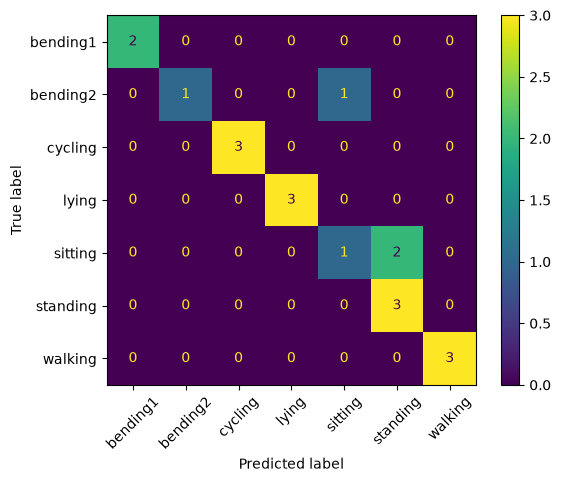

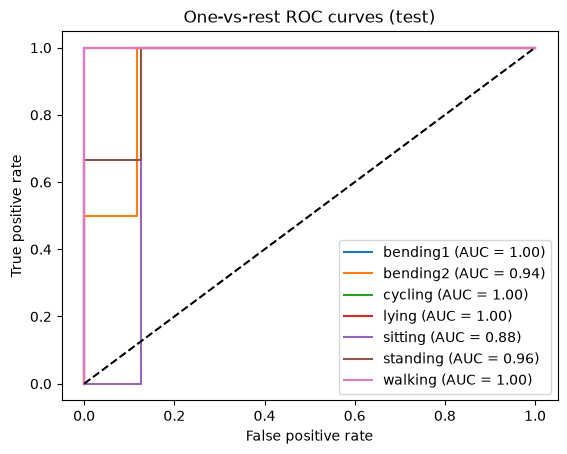

In [13]:
best_lm, best_Cm = 2, 1.0

X_tr = make_features(train_dfs, best_lm)
X_te = make_features(test_dfs, best_lm)
scaler_m = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler_m.transform(X_tr), scaler_m.transform(X_te)

multi = LogisticRegression(penalty="l1", solver="saga", C=best_Cm, max_iter=1000).fit(X_tr_s, train_act)
pred = multi.predict(X_te_s)
print("Test error:", 1 - accuracy_score(test_act, pred))

ConfusionMatrixDisplay.from_predictions(test_act, pred, labels=multi.classes_, xticks_rotation=45)
plt.show()

prob = multi.predict_proba(X_te_s)
Y_te = label_binarize(test_act, classes=multi.classes_)
for k, name in enumerate(multi.classes_):
    fpr, tpr, _ = roc_curve(Y_te[:, k], prob[:, k])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC curves (test)")
plt.legend()
plt.show()

Best l = 2 (with C = 1), chosen by stratified 5-fold cross-validation (CV accuracy 0.914).

#### ii. Naive Bayes

In [14]:
nb_models = {
    "Gaussian": Pipeline([("scale", StandardScaler()), ("nb", GaussianNB())]),
    "Multinomial": Pipeline([("scale", MinMaxScaler(clip=True)), ("nb", MultinomialNB())]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for l in range(1, 21):
    X_l = make_features(train_dfs, l)
    for name, model in nb_models.items():
        acc = cross_val_score(model, X_l, train_act, cv=cv).mean()
        rows.append((name, l, acc))

res_nb = pd.DataFrame(rows, columns=["model", "l", "cv_accuracy"])
cv_table = res_nb.pivot(index="l", columns="model", values="cv_accuracy")
display(cv_table)
print(cv_table.idxmax())

model,Gaussian,Multinomial
l,,
1,0.857143,0.737363
2,0.827473,0.751648
3,0.681319,0.723077
4,0.725275,0.708791
5,0.652747,0.723077
6,0.652747,0.680220
7,0.680220,0.694505
8,0.681319,0.680220
9,0.638462,0.680220


model
Gaussian       1
Multinomial    2
dtype: int64


Gaussian NB, l = 1 , test error: 0.10526315789473684


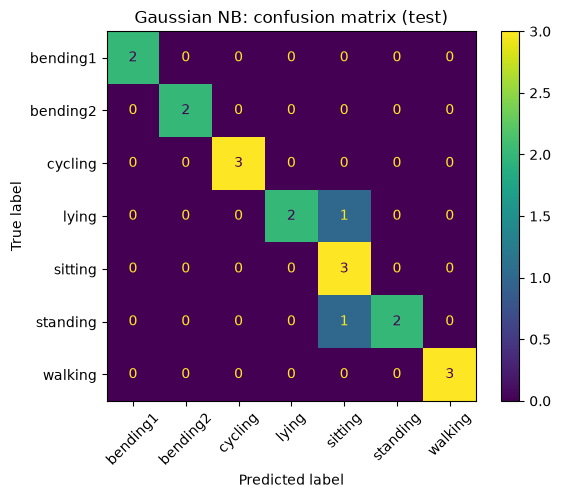

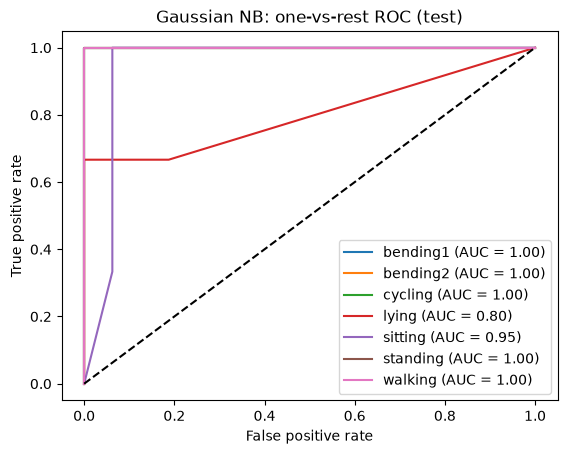

Multinomial NB, l = 2 , test error: 0.21052631578947367


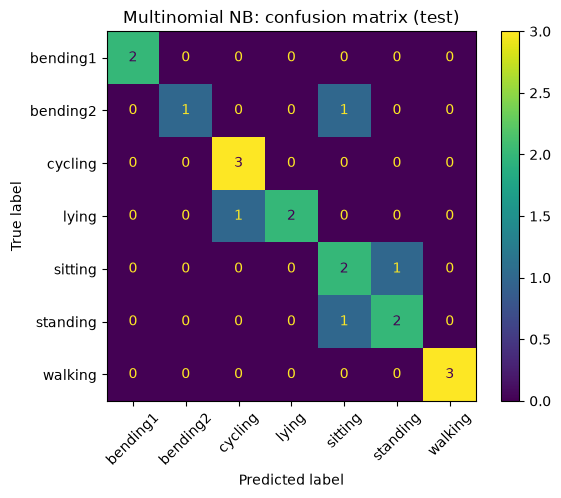

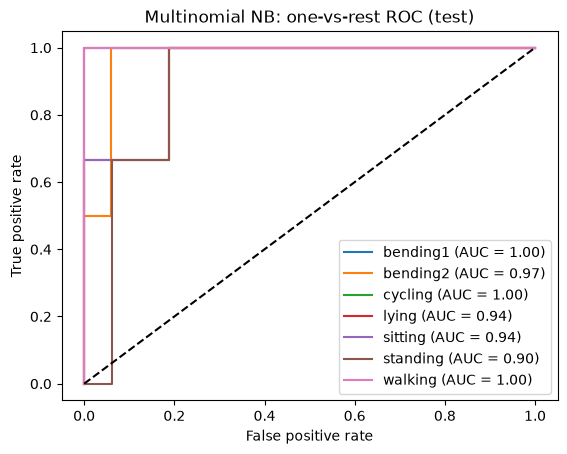

In [15]:
best_nb = {"Gaussian": 1, "Multinomial": 2}

for name, model in nb_models.items():
    l = best_nb[name]
    Xtr, Xte = make_features(train_dfs, l), make_features(test_dfs, l)
    model.fit(Xtr, train_act)
    pred = model.predict(Xte)
    print(name, "NB, l =", l, ", test error:", 1 - accuracy_score(test_act, pred))

    ConfusionMatrixDisplay.from_predictions(test_act, pred, labels=model.classes_, xticks_rotation=45)
    plt.title(f"{name} NB: confusion matrix (test)")
    plt.show()

    prob = model.predict_proba(Xte)
    Y_te = label_binarize(test_act, classes=model.classes_)
    for k, cls in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(Y_te[:, k], prob[:, k])
        plt.plot(fpr, tpr, label=f"{cls} (AUC = {auc(fpr, tpr):.2f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{name} NB: one-vs-rest ROC (test)")
    plt.legend()
    plt.show()

Gaussian NB (best l = 1) has a cross-validation accuracy of 0.857 and a test error of 0.105. Multinomial NB (best l = 2) has a cross-validation accuracy of 0.752 and a test error of 0.211. Gaussian NB is clearly better, because Multinomial NB is designed for count data and not for continuous features like these.

#### iii. Comparison

L1-penalized multinomial logistic regression is the best method overall. It has the highest cross-validation accuracy (0.914, vs. 0.857 for Gaussian NB and 0.752 for Multinomial NB), and the cross-validation accuracy is estimated on 69 training instances, so it is more reliable than the test error. Its test error (0.158, 3 of 19 misclassified) is between Gaussian NB (0.105) and Multinomial NB (0.211). Gaussian NB has the lowest test error, but the difference from L1 is only one test instance out of 19, which is not significant. Multinomial NB is clearly the worst. Most errors of all models occur among the static activities (lying, sitting, standing). L1-penalized logistic regression and Multinomial NB also misclassify one bending2 instance as sitting or standing.

## 3. ISLR 4.8.3

For an observation $X = x$, the Bayes classifier assigns it to the class $k$ with the largest posterior probability

$$p_k(x) = \frac{\pi_k \frac{1}{\sqrt{2\pi}\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)}{\sum_{l=1}^K \pi_l \frac{1}{\sqrt{2\pi}\sigma_l}\exp\left(-\frac{(x-\mu_l)^2}{2\sigma_l^2}\right)}.$$

The denominator is the same for all classes, so we only need to maximize the numerator. Taking the log (which is increasing) and dropping the term $-\frac{1}{2}\log(2\pi)$ that is common to all classes, we assign $x$ to the class with the largest

$$\delta_k(x) = \log \pi_k - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$


$$\delta_k(x) = -\frac{1}{2\sigma_k^2}x^2 + \frac{\mu_k}{\sigma_k^2}x - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k .$$

The coefficient of $x^2$ is $-\frac{1}{2\sigma_k^2}$, which depends on $k$ because the variances are not assumed to be equal. Therefore $\delta_k(x)$ is a quadratic function of $x$, not a linear one. The decision boundary between classes $k$ and $l$ is the set of $x$ with $\delta_k(x) = \delta_l(x)$, i.e.

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + c = 0,$$

which is a quadratic equation in $x$ whenever $\sigma_k \neq \sigma_l$. Hence the Bayes classifier is quadratic, not linear. (In the special case $\sigma_1^2 = \dots = \sigma_K^2$, the $x^2$ terms cancel and we recover the linear discriminant function of LDA.)

## 4. ISLR 4.8.7

By Bayes' theorem, with $\pi_{Yes}=0.8$, $\pi_{No}=0.2$, $\mu_{Yes}=10$, $\mu_{No}=0$ and a common variance $\sigma^2=36$,

$$P(Yes \mid X=4) = \frac{\pi_{Yes}\, f_{Yes}(4)}{\pi_{Yes}\, f_{Yes}(4) + \pi_{No}\, f_{No}(4)}.$$

Since the two classes have the same variance, the Gaussian normalizing constants cancel, and

$$P(Yes \mid X=4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} \approx \frac{0.4852}{0.4852 + 0.1601} \approx 0.752.$$

So the probability that the company issues a dividend is about 75.2%, and we predict "Yes".

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9